In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.callbacks import EarlyStopping

In [13]:
df = pd.read_csv("Customer_Churn_Sampling.csv")
print(df.head())

   RowNumber  CustomerId   Surname  CreditScore Geography  Gender  Age  \
0          1    15634602  Hargrave          619    France  Female   42   
1          2    15647311      Hill          608     Spain  Female   41   
2          3    15619304      Onio          502    France  Female   42   
3          4    15701354      Boni          699    France  Female   39   
4          5    15737888  Mitchell          850     Spain  Female   43   

   Tenure    Balance  NumOfProducts  HasCrCard  IsActiveMember  \
0       2       0.00              1          1               1   
1       1   83807.86              1          0               1   
2       8  159660.80              3          1               0   
3       1       0.00              2          0               0   
4       2  125510.82              1          1               1   

   EstimatedSalary  Exited  
0        101348.88       1  
1        112542.58       0  
2        113931.57       1  
3         93826.63       0  
4         790

In [14]:
print(df.shape)
print(df.columns)
print(df.info())

(10000, 14)
Index(['RowNumber', 'CustomerId', 'Surname', 'CreditScore', 'Geography',
       'Gender', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard',
       'IsActiveMember', 'EstimatedSalary', 'Exited'],
      dtype='str')
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  str    
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  str    
 5   Gender           10000 non-null  str    
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  100

In [15]:
df.isnull().sum()

RowNumber          0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64

In [16]:
X = df.drop(['RowNumber', 'CustomerId', 'Surname', 'Exited'], axis = 1)
y = df['Exited']

In [17]:
print("Shape of X: ", X.shape)
print("\nShape of Y: ", y.shape)

Shape of X:  (10000, 10)

Shape of Y:  (10000,)


In [18]:
X.head()
X.columns

Index(['CreditScore', 'Geography', 'Gender', 'Age', 'Tenure', 'Balance',
       'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary'],
      dtype='str')

In [19]:
X = pd.get_dummies(
    X,
    columns = ['Geography', 'Gender'],
    drop_first = True,
    dtype = int
)

print("Features after encoding: ")
X.head()

print("\nFeature Shape : ", X.shape)
print("\nTarget Shape : ", y.shape)

Features after encoding: 

Feature Shape :  (10000, 11)

Target Shape :  (10000,)


In [20]:
X.head()

,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Geography_Germany,Geography_Spain,Gender_Male
0,619,42,2,0.00,1,1,1,101348.88,0,0,0
1,608,41,1,83807.86,1,0,1,112542.58,0,1,0
2,502,42,8,159660.80,3,1,0,113931.57,0,0,0
3,699,39,1,0.00,2,0,0,93826.63,0,0,0
4,850,43,2,125510.82,1,1,1,79084.10,0,1,0


In [21]:
#Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size = 0.2, random_state = 42, stratify = y
)

print("Shape of Training Data: ", X_train.shape)
print("Shape of Testing Data: ", X_test.shape)

Shape of Training Data:  (8000, 11)
Shape of Testing Data:  (2000, 11)


In [22]:
sc = StandardScaler()
X_train = sc.fit_transform(X_train)
X_test = sc.transform(X_test)

print("Normalization done !!")

Normalization done !!


In [23]:
model = Sequential([
    Input(shape = (X_train.shape[1], )),
    Dense(16, activation = 'relu'),
    Dense(8, activation = 'relu'),
    Dense(1, activation = 'sigmoid')
])

In [24]:
model.compile(
    optimizer = 'adam',
    loss = 'binary_crossentropy',
    metrics = ['accuracy']
)

In [25]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 16)                  │             192 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 8)                   │             136 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 1)                   │               9 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 337 (1.32 KB)

 Trainable params: 337 (1.32 KB)

 Non-trainable params: 0 (0.00 B)

In [26]:
history = model.fit(
    X_train,
    y_train,
    epochs = 20,
    batch_size = 32,
    validation_split = 0.2,
    verbose = 1
)

Epoch 1/20
200/200 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.7773 - loss: 0.5087 - val_accuracy: 0.8069 - val_loss: 0.4413
Epoch 2/20
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8075 - loss: 0.4338 - val_accuracy: 0.8219 - val_loss: 0.4185
Epoch 3/20
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8234 - loss: 0.4106 - val_accuracy: 0.8344 - val_loss: 0.4009
Epoch 4/20
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8341 - loss: 0.3929 - val_accuracy: 0.8456 - val_loss: 0.3835
Epoch 5/20
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8414 - loss: 0.3782 - val_accuracy: 0.8575 - val_loss: 0.3685
Epoch 6/20
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8492 - loss: 0.3671 - val_accuracy: 0.8612 - val_loss: 0.3576
Epoch 7/20
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8500 - loss: 0.3593 - val_accuracy: 0.8606 - val_loss: 0.3510
Epoch 8/20
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8505 - loss: 0.3543 - val_accuracy: 0.

In [28]:
# Evaluation
y_pred_prob = model.predict(X_test)
y_pred = (y_pred_prob > 0.5).astype(int).flatten()

basic_accuracy = accuracy_score(y_test, y_pred)

print("Basic Accuracy Score: ", round(basic_accuracy*100, 2), "%")

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step
Basic Accuracy Score:  85.5 %


In [29]:
print("Basic Model Confusion Matrix: ")
print(confusion_matrix(y_test, y_pred))

Basic Model Confusion Matrix: 
[[1543   50]
 [ 240  167]]


In [30]:
print("Basic Model Classification Report: ")
print(classification_report(y_test, y_pred))

Basic Model Classification Report: 
              precision    recall  f1-score   support

           0       0.87      0.97      0.91      1593
           1       0.77      0.41      0.54       407

    accuracy                           0.85      2000
   macro avg       0.82      0.69      0.72      2000
weighted avg       0.85      0.85      0.84      2000



In [31]:
improved_model = Sequential([
    Input(shape=(X_train.shape[1],)),
    Dense(32, activation = 'relu'),
    Dense(16, activation = 'relu'),
    Dense(1, activation = 'sigmoid')
])

In [32]:
improved_model.compile(
    optimizer = 'adam',
    loss = 'binary_crossentropy',
    metrics = ['accuracy']
)

In [33]:
improved_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                      │ (None, 32)                  │             384 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_4 (Dense)                      │ (None, 16)                  │             528 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_5 (Dense)                      │ (None, 1)                   │              17 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 929 (3.63 KB)

 Trainable params: 929 (3.63 KB)

 Non-trainable params: 0 (0.00 B)

In [35]:
early_stop = EarlyStopping(
    monitor = 'val_loss',
    patience = 3,
    restore_best_weights = True
)

In [36]:
improved_history = improved_model.fit(X_train, y_train, epochs = 50, batch_size = 32, validation_split = 0.2, callbacks = [early_stop], verbose = 1)

Epoch 1/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.7802 - loss: 0.4924 - val_accuracy: 0.8181 - val_loss: 0.4319
Epoch 2/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8142 - loss: 0.4224 - val_accuracy: 0.8263 - val_loss: 0.4100
Epoch 3/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8267 - loss: 0.4012 - val_accuracy: 0.8487 - val_loss: 0.3868
Epoch 4/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8411 - loss: 0.3814 - val_accuracy: 0.8625 - val_loss: 0.3625
Epoch 5/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8494 - loss: 0.3660 - val_accuracy: 0.8637 - val_loss: 0.3494
Epoch 6/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8522 - loss: 0.3570 - val_accuracy: 0.8737 - val_loss: 0.3401
Epoch 7/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8555 - loss: 0.3510 - val_accuracy: 0.8712 - val_loss: 0.3366
Epoch 8/50
200/200 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.8580 - loss: 0.3470 - val_accuracy: 0.

In [37]:
y_pred_improved_prob = improved_model.predict(X_test)
y_pred_improved = (y_pred_improved_prob > 0.5).astype(int).flatten()

63/63 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step


In [38]:
improved_accuracy = accuracy_score(y_test, y_pred_improved)

In [39]:
print("Improved Model Accuracy Score : ", round(improved_accuracy * 100, 2), "%")

Improved Model Accuracy Score :  86.3 %


In [40]:
print("Improved Model Confusion Matrix: ")
print(confusion_matrix(y_test, y_pred_improved))

Improved Model Confusion Matrix: 
[[1527   66]
 [ 208  199]]


In [41]:
print("Improved Model Classification Report: ")
print(classification_report(y_test, y_pred_improved))

Improved Model Classification Report: 
              precision    recall  f1-score   support

           0       0.88      0.96      0.92      1593
           1       0.75      0.49      0.59       407

    accuracy                           0.86      2000
   macro avg       0.82      0.72      0.75      2000
weighted avg       0.85      0.86      0.85      2000



In [42]:
print("\n----- Model Comparison -----\n")
print("Basic Model Accuracy: ", round(basic_accuracy * 100, 2), "%")
print("Improved Model Accuracy:",
      round(improved_accuracy * 100, 2), "%")
if improved_accuracy > basic_accuracy:
    print("\nImproved Model performs better.")
elif improved_accuracy < basic_accuracy:
    print("\nBasic Model performs better.")
else:
    print("\nBoth models have equal accuracy.")


----- Model Comparison -----

Basic Model Accuracy:  85.5 %
Improved Model Accuracy: 86.3 %

Improved Model performs better.


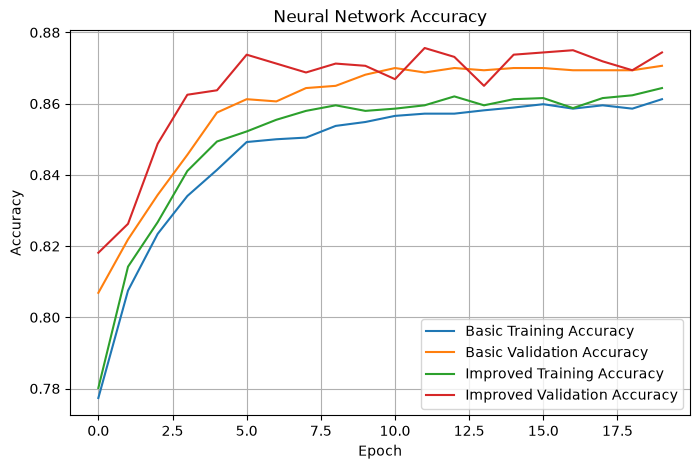

In [43]:

# Section 13: Visualize Training and Validation Accuracy

plt.figure(figsize=(8, 5))

plt.plot(
    history.history['accuracy'],
    label='Basic Training Accuracy'
)

plt.plot(
    history.history['val_accuracy'],
    label='Basic Validation Accuracy'
)

plt.plot(
    improved_history.history['accuracy'],
    label='Improved Training Accuracy'
)

plt.plot(
    improved_history.history['val_accuracy'],
    label='Improved Validation Accuracy'
)

plt.title('Neural Network Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')

plt.legend()
plt.grid(True)
plt.show()